# Logistic Regression: Spam Classification

Implementing Logistic Regression from scratch using NumPy.

**Goal:** Predict whether an email is Spam (1) or Not Spam (0).

## 1. Import Libraries

Import NumPy for numerical computations.

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

## 2. Create Dataset

Features:
- Links
- Spam words
- Unknown sender

Target:
- 0 = Not Spam
- 1 = Spam

In [2]:
X = np.array([
    [0, 0, 0],
    [1, 0, 0],
    [2, 1, 0],
    [5, 3, 1],
    [4, 4, 1],
    [0, 3, 1],
    [1, 1, 0],
    [6, 5, 1]
])

y = np.array([0, 0, 0, 1, 1, 1, 0, 1])
print(f"X shape : {X.shape} | Y shape {y.shape}")

X shape : (8, 3) | Y shape (8,)


## 3. Implement Sigmoid Function

Formula:

σ(z) = 1 / (1 + e^(-z))

Convert numerical scores into probabilities between 0 and 1.

In [3]:
def sigmoid(z):
    return 1/(1+np.exp(-z))

print("done")

done


## 4. Test Sigmoid Function

Test with positive, negative, and zero inputs.

In [4]:
print(sigmoid(0))
print(sigmoid(2))
print(sigmoid(-2))

0.5
0.8807970779778823
0.11920292202211755


## 5. Initialize Model Parameters

Initialize weights and bias for our three input features.

In [5]:
n_features = X.shape[1]

w = np.zeros(n_features)
b = 0.0

print("Weights:", w)
print("Bias:", b)

Weights: [0. 0. 0.]
Bias: 0.0


## 6. Calculate Linear Combination

Calculate the weighted sum of input features.

Formula:

z = Xw + b

In [6]:
z = X @ w + b

print("Linear scores:", z)

Linear scores: [0. 0. 0. 0. 0. 0. 0. 0.]


## 7. Calculate Spam Probabilities

Apply the sigmoid function to convert linear scores into probabilities.

In [7]:
probabilities = sigmoid(z)

print("Spam probabilities:", probabilities)

Spam probabilities: [0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5]


## 8. Implement Prediction Function

Calculate the probability of an email being spam using the
linear combination of features, weights, and bias.

Formula:

z = Xw + b

P(y = 1 | X) = σ(z)

In [8]:
def predict_proba(x,w,b):
    Z = x@w + b
    return sigmoid(Z)
print("Done")


Done


## 9. Convert Probabilities into Classes

Use a threshold of 0.5 to classify emails.

- 0 = Not Spam
- 1 = Spam

In [9]:
def predict_class(X, w, b, threshold=0.5):
    p = predict_proba(X, w, b)
    pred_class = (p >= threshold).astype(int)
    return pred_class
print("Done")

Done


## 10. Test Initial Predictions

Check the predictions before training the model.

In [10]:
probabilities = predict_proba(X, w, b)
predictions = predict_class(X, w, b)

print("Probabilities:", probabilities)
print("Predictions:", predictions)
print("Actual labels:", y)

Probabilities: [0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5]
Predictions: [1 1 1 1 1 1 1 1]
Actual labels: [0 0 0 1 1 1 0 1]


## 11. Calculate Binary Cross-Entropy Loss

Measure the difference between actual labels and predicted probabilities.

Formula:

L = -1/m Σ [y log(p) + (1-y) log(1-p)]

Where:
- m = Number of training samples
- y = Actual label
- p = Predicted probability

In [11]:
def binary_loss(y,p):
    n = len(y)
    loss = -(1/n) * np.sum(
    y * np.log(p) + (1-y) * np.log(1-p)
)
    return loss
print("Done")


Done


## 12. Implement Gradient Descent

Calculate gradients to update model weights and bias.

Weight gradient:

dw = (1/m) Xᵀ(p-y)

Bias gradient:

db = (1/m) Σ(p-y)

In [12]:
def train(x,y):
    w = np.zeros(x.shape[1])
    b = 0.0
    lr = 0.1
    n = len(x)
    epochs = 100
    loss_history = []
    for epoch in range(epochs):
        p = predict_proba(x,w,b)

        loss = binary_loss(y,p)

        dw =(1/n)*x.T@(p-y)
        db = (1/n)*np.sum(p-y)

        w -= lr*dw
        b -= lr*db

        loss_history.append(loss)
    return w,b, loss_history
print("Done")

Done


### 13. Testing the impletations

In [13]:
w,b,loss_history = train(X,y)
pred = predict_proba(X,w,b)
pred_class = predict_class(X,w,b)
loss = binary_loss(y,pred)
print("Done")


Done


## 14. Visualize Training Loss

Plot the Binary Cross-Entropy loss against the number of epochs.

Observe how the loss changes as the model updates its weights and bias.

A decreasing loss indicates that the model is improving its predictions on the training data.

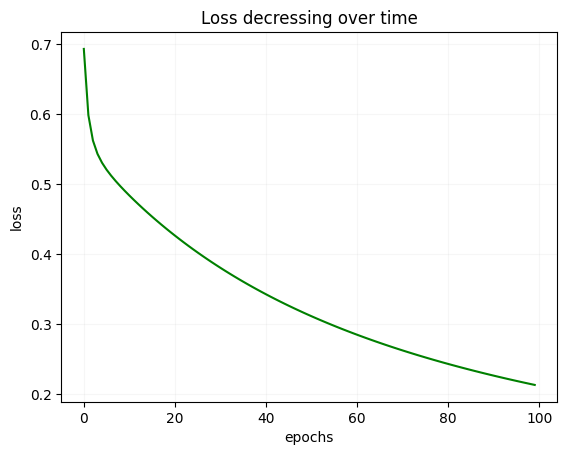

In [14]:
plt.plot(loss_history,color = "green")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.grid(True,alpha = 0.1)
plt.title("Loss decressing over time")
plt.show()

## 14. Generate Final Predictions

Use the trained weights and bias to calculate spam probabilities.

Convert probabilities into binary predictions using a threshold of 0.5.

- 0 = Not Spam
- 1 = Spam

Compare predicted labels with actual labels.

In [15]:
print("Trained predictions :",pred)
print("Trained predict class :",pred_class)
print("Actual class :",y)
print("Loss :",loss)

Trained predictions : [0.20218446 0.18255351 0.35167615 0.8426009  0.94364408 0.9096965
 0.38101686 0.97285597]
Trained predict class : [0 0 0 1 1 1 0 1]
Actual class : [0 0 0 1 1 1 0 1]
Loss : 0.2114901782445684


## 15. Evaluate Model Performance

Evaluate the trained Logistic Regression model using:

- Accuracy
- Precision
- Recall
- F1-Score

These metrics help us understand how well the model identifies Spam and Not Spam emails.

## 16. Confusion Matrix

A confusion matrix compares actual labels with predicted labels.

It contains four outcomes:

- True Positive (TP): Actual Spam, predicted Spam.
- True Negative (TN): Actual Not Spam, predicted Not Spam.
- False Positive (FP): Actual Not Spam, predicted Spam.
- False Negative (FN): Actual Spam, predicted Not Spam.

Use these values to calculate classification metrics.

## 17. Classification Metrics

**Accuracy:** Overall percentage of correct predictions.

Accuracy = (TP + TN) / (TP + TN + FP + FN)

**Precision:** Out of all emails predicted as Spam, how many were actually Spam?

Precision = TP / (TP + FP)

**Recall:** Out of all actual Spam emails, how many did the model identify?

Recall = TP / (TP + FN)

**F1-Score:** Harmonic mean of Precision and Recall.

F1 = 2 × (Precision × Recall) / (Precision + Recall)

In [18]:
def confusion_matrix(y_true,y_pred):
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))

    accuracy = (tp+tn) / (tp+tn+fp+fn)
    recall = tp/(tp+fn) if (tp+fp) != 0 else 0
    precision = tp/(tp+fp) if (tp + fp) != 0 else 0

    f1_score = 2*(precision*recall)/(precision + recall) if (precision + recall ) != 0 else 0

    cm = np.array([
        [tn,fp],
        [fn,tp]
    ])

    return accuracy,recall , precision, f1_score,cm
print("Done")


Done


In [21]:
accuracy,recall,precision,f1_score,cm = confusion_matrix(y,pred_class)
print(f"Acuuracy : {(accuracy)*100}%")
print(f"Recall : {recall}")
print(f"Precision : {precision}")
print(f"f1 score : {f1_score}")
print(f"Cm :{cm}")

Acuuracy : 100.0%
Recall : 1.0
Precision : 1.0
f1 score : 1.0
Cm :[[4 0]
 [0 4]]


## 18. Confusion Matrix Visualization

Visualize the confusion matrix using Matplotlib.

Understand:
- Correct classifications.
- Incorrect classifications.
- False positives and false negatives.

A good classifier should minimize both types of errors.

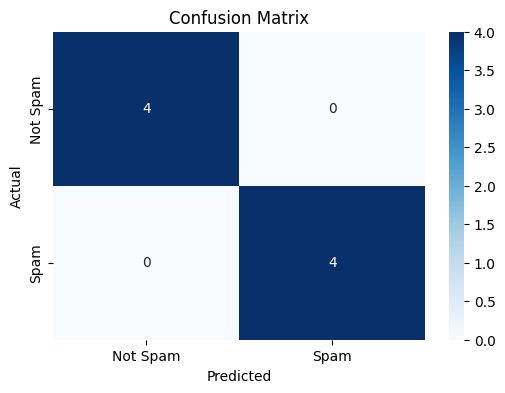

In [ ]:
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Spam", "Spam"],
    yticklabels=["Not Spam", "Spam"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

## 19. Test with New Examples

Test the trained Logistic Regression model using unseen email examples.

Each example contains:
- Number of links.
- Number of spam-related words.
- Unknown sender (0 or 1).

Generate:
- Spam probability.
- Predicted class.
- Final classification (Spam / Not Spam).

Use a decision threshold of 0.5.

In [ ]:
new_emails = np.array([
    [0, 0, 0],
    [5, 4, 1],
    [2, 0, 1],
    [6, 5, 1]
])

new_pred = predict_proba(new_emails,w,b)
new_pred_class = predict_class(new_emails,w,b)

print("New prediction class :",new_pred_class)

New prediction class : [0 1 0 1]


## 20. Save the Trained Model

Save the trained Logistic Regression parameters for future use.

The model consists of:

- Weights (w)
- Bias (b)

Use NumPy's `np.savez()` to store the parameters inside the `model/` directory.

The saved parameters can later be loaded without training the model again.

In [ ]:
model_dir = os.path.join(os.getcwd(),"model")
os.makedirs(model_dir,exist_ok = True)
model_path = os.path.join(model_dir,"Spam_classifier.npz")
np.savez(model_path , w = w , b = b)
print("Model Saved succesffully")

Model Saved succesffully


# Logistic Regression — Spam vs Not Spam Classification

## Project Overview

Implemented a Binary Logistic Regression model from scratch using NumPy to classify emails as Spam or Not Spam.

## Implementation

- Dataset creation and feature preparation
- Sigmoid activation function
- Probability prediction
- Binary Cross-Entropy loss
- Gradient Descent optimization
- Weight and bias updates
- Binary classification using a 0.5 threshold
- Confusion matrix
- Accuracy, Precision, Recall and F1-Score
- Confusion matrix visualization
- Predictions on new examples
- Model parameter saving

## Results

- Training samples: 8
- Training accuracy: 100%
- Training loss: 0.21149
- New examples tested: 4

**Note:** The reported accuracy is training accuracy, not test accuracy. The four new examples were unlabeled, so their predictions cannot be independently evaluated.

## Technologies

- Python
- NumPy
- Matplotlib
- Seaborn

## Key Learning

This exercise established the mathematical and practical foundations of Logistic Regression, including probability estimation, optimization through Gradient Descent, and classification evaluation.

**Implementation:** From Scratch — No Scikit-learn or TensorFlow.
